In [3]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

sns.set_theme(style="whitegrid")

base_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
db_path = base_dir / "data" / "empleados_limpio.db"
fig_dir = base_dir / "docs" / "figuras"
fig_dir.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect(db_path)
tablas = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn)
print("Tablas en la BD:", tablas["name"].tolist())

tabla_objetivo = "empleados" if "empleados" in tablas["name"].tolist() else tablas["name"].iloc[0]
df = pd.read_sql(f"SELECT * FROM {tabla_objetivo}", conn)
conn.close()

df.columns = [c.strip().lower() for c in df.columns]
var_objetivo = "salario_mensual" if "salario_mensual" in df.columns else df.select_dtypes(include=np.number).columns[0]
num_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Shape:", df.shape)
display(df.head())

Tablas en la BD: ['empleados']
Shape: (27, 13)


,empleado_id,nombre,edad,rango_edad,departamento,ciudad,anios_experiencia,antiguedad_empresa,salario_mensual,ratio_salario_exp,satisfaccion_laboral,fecha_ingreso,es_atipico_salario
0,EMP-001,Empleado 1,23,18-25,Finanzas,Monterrey,6.0,4.0,29501.0,4916.83,3.0,2018-01-10,0
1,EMP-002,Empleado 2,50,46+,Rrhh,Cdmx,2.0,7.0,44744.0,22372.00,3.0,2018-04-15,0
2,EMP-003,Empleado 3,46,46+,Rrhh,Guadalajara,12.0,2.0,36150.0,3012.50,3.0,2018-07-19,0
3,EMP-004,Empleado 4,37,36-45,Rrhh,Cdmx,9.0,7.0,31722.0,3524.67,5.0,2018-10-22,0
4,EMP-005,Empleado 5,37,36-45,Ti,Guadalajara,10.0,5.0,36272.0,3627.20,2.0,2019-01-25,0


In [6]:
# Celda 2: Medidas descriptivas generales y por grupo
print(f"=== Descriptivas de {var_objetivo} ===")
display(df[var_objetivo].agg(["count", "mean", "median", "std", "min", "max"]).to_frame().T.round(2))

if "departamento" in df.columns:
    print(f"\n=== {var_objetivo} por departamento ===")
    desc_depto = df.groupby("departamento", dropna=False)[var_objetivo].agg(
        conteo="count",
        media="mean",
        mediana="median",
        desv_std="std",
        minimo="min",
        maximo="max"
    ).round(2)
    display(desc_depto)

if "ciudad" in df.columns:
    print(f"\n=== {var_objetivo} por ciudad ===")
    desc_ciudad = df.groupby("ciudad", dropna=False)[var_objetivo].agg(
        conteo="count",
        media="mean",
        mediana="median",
        desv_std="std"
    ).round(2)
    display(desc_ciudad)

=== Descriptivas de salario_mensual ===


,count,mean,median,std,min,max
salario_mensual,27.0,50004.19,39755.0,48327.92,15769.0,280000.0



=== salario_mensual por departamento ===


,conteo,media,mediana,desv_std,minimo,maximo
departamento,,,,,,
Finanzas,6,42747.00,38629.0,16135.08,28103.0,64625.0
Operaciones,6,76202.50,41081.5,100961.48,16973.0,280000.0
Rrhh,6,36931.33,36150.0,8401.99,24943.0,47879.0
Ti,4,36298.00,32311.0,20792.89,15769.0,64801.0
Ventas,5,53927.20,55905.0,11397.07,34834.0,64119.0



=== salario_mensual por ciudad ===


,conteo,media,mediana,desv_std
ciudad,,,,
Cdmx,6,38357.33,37952.5,14509.35
Guadalajara,7,47311.43,47757.0,14424.70
Monterrey,9,38110.22,34834.0,16097.60
Puebla,5,89159.40,47879.0,107874.55


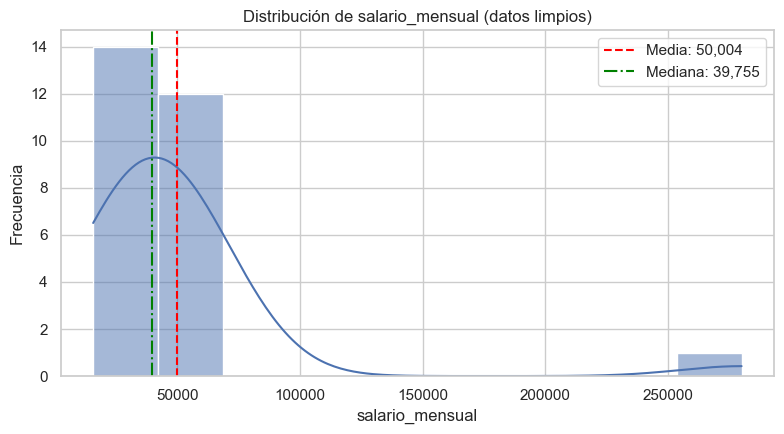

In [7]:
# Celda 3: Histograma y densidad de la variable objetivo
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df, x=var_objetivo, kde=True, bins=10, ax=ax)
media_val = df[var_objetivo].mean()
mediana_val = df[var_objetivo].median()
ax.axvline(media_val, color="red", linestyle="--", label=f"Media: {media_val:,.0f}")
ax.axvline(mediana_val, color="green", linestyle="-.", label=f"Mediana: {mediana_val:,.0f}")
ax.set_title(f"Distribución de {var_objetivo} (datos limpios)")
ax.set_xlabel(var_objetivo)
ax.set_ylabel("Frecuencia")
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "fig1_distribucion_salario.png", dpi=150)
plt.show()

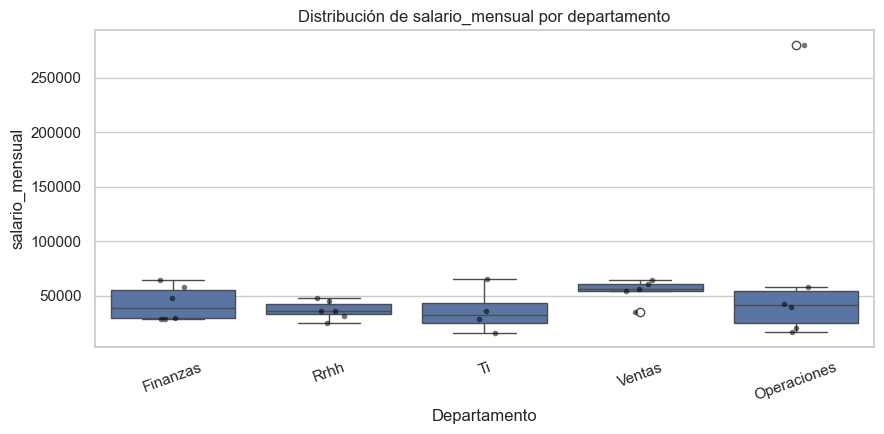

In [8]:
# Celda 4: Boxplot + puntos por departamento
if "departamento" in df.columns:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.boxplot(data=df, x="departamento", y=var_objetivo, ax=ax)
    sns.stripplot(data=df, x="departamento", y=var_objetivo, color="black", alpha=0.55, size=4, ax=ax)
    ax.set_title(f"Distribución de {var_objetivo} por departamento")
    ax.set_xlabel("Departamento")
    ax.set_ylabel(var_objetivo)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(fig_dir / "fig2_boxplot_salario_departamento.png", dpi=150)
    plt.show()

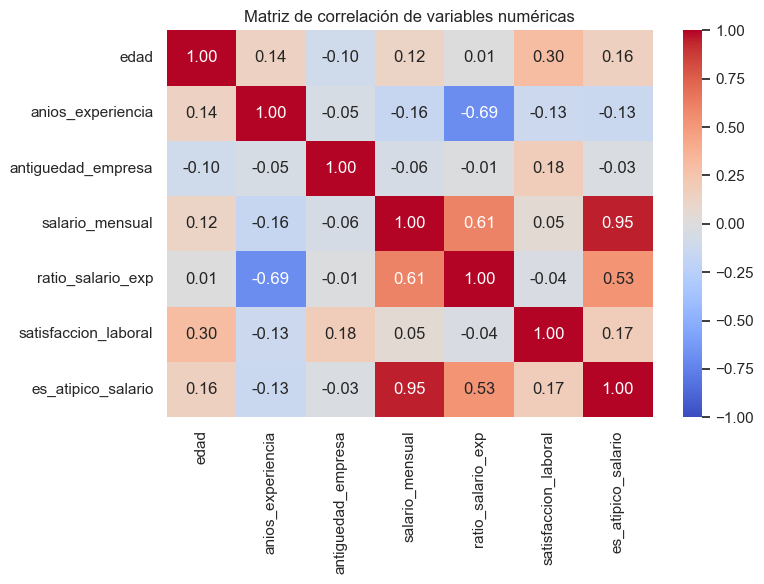

In [9]:
# Celda 5: Matriz de correlación (heatmap)
corr = df[num_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.savefig(fig_dir / "fig3_heatmap_correlacion.png", dpi=150)
plt.show()

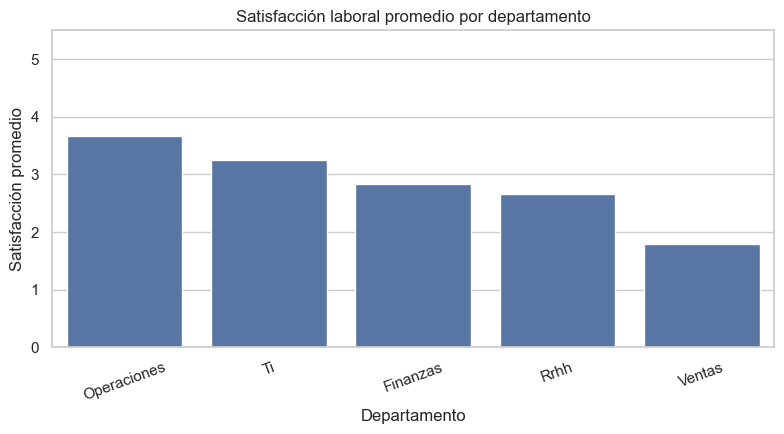

In [10]:
# Celda 6: Comparación adicional (satisfacción laboral por departamento o ciudad)
cat_comp = "departamento" if "departamento" in df.columns else ("ciudad" if "ciudad" in df.columns else None)
if cat_comp and "satisfaccion_laboral" in df.columns:
    sat_resumen = df.groupby(cat_comp, as_index=False)["satisfaccion_laboral"].mean().sort_values("satisfaccion_laboral", ascending=False)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.barplot(data=sat_resumen, x=cat_comp, y="satisfaccion_laboral", ax=ax)
    ax.set_ylim(0, 5.5)
    ax.set_title(f"Satisfacción laboral promedio por {cat_comp}")
    ax.set_xlabel(cat_comp.capitalize())
    ax.set_ylabel("Satisfacción promedio")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(fig_dir / "fig4_satisfaccion_categoria.png", dpi=150)
    plt.show()

In [11]:
# Celda 7: Gráfico interactivo con Plotly (experiencia vs salario)
x_col = "anios_experiencia" if "anios_experiencia" in df.columns else num_cols[0]
color_col = "departamento" if "departamento" in df.columns else None
hover_cols = [c for c in ["nombre", "ciudad", "satisfaccion_laboral"] if c in df.columns]

fig_px = px.scatter(
    df,
    x=x_col,
    y=var_objetivo,
    color=color_col,
    hover_data=hover_cols,
    title=f"Relación entre {x_col} y {var_objetivo} (interactivo)"
)
fig_px.write_html(fig_dir / "fig5_interactiva_exp_salario.html")
fig_px.show()

In [5]:
# Celda 8: Prueba de hipótesis (comparación entre los dos departamentos más frecuentes)

if "departamento" in df.columns and df["departamento"].nunique() >= 2:
    top2 = df["departamento"].value_counts().index[:2].tolist()
    g1 = df.loc[df["departamento"] == top2[0], var_objetivo].dropna()
    g2 = df.loc[df["departamento"] == top2[1], var_objetivo].dropna()

    t_stat, p_val_t = stats.ttest_ind(g1, g2, equal_var=False)
    u_stat, p_val_u = stats.mannwhitneyu(g1, g2, alternative="two-sided")

    print(f"Comparando '{top2[0]}' (n={len(g1)}, media={g1.mean():,.2f}, mediana={g1.median():,.2f}) "
          f"vs '{top2[1]}' (n={len(g2)}, media={g2.mean():,.2f}, mediana={g2.median():,.2f})")
    print(f"Welch t-test: estadístico={t_stat:.4f}, p-value={p_val_t:.4f}")
    print(f"Mann-Whitney U: estadístico={u_stat:.4f}, p-value={p_val_u:.4f}")

Comparando 'Finanzas' (n=6, media=42,747.00, mediana=38,629.00) vs 'Rrhh' (n=6, media=36,931.33, mediana=36,150.00)
Welch t-test: estadístico=0.7831, p-value=0.4575
Mann-Whitney U: estadístico=20.0000, p-value=0.8099
